# In-class work 10. Tuning a PID controller with a genetic algorithm and a particle swarm

Industrial AI, KBTU. Goes with Lecture 10, "PID tuning via artificial intelligence
methods".

The object is a heat-treatment furnace. A PID controller holds its temperature by moving the gas
valve. Opening the valve by 1 % raises the temperature by 1.5 °C once everything settles. The
furnace answers with a time constant of 200 s, and for the first 40 s nothing happens at all: the
gas has to reach the burner and the heat has to reach the thermocouple. This is a **first order
plus dead time** (FOPDT) object, the model engineers fit to most temperature, level and flow
loops.

Three numbers, $K_p$, $K_i$ and $K_d$, decide how the furnace answers a setpoint change of 10 °C.
Classical rules give them in one line, and last week's optimisers can search for them. We compare
the two, decide by which measure one tuning is better than another, and see what happens when the
dead time turns out longer than the model says.

1. the loop and what each term of the PID does;
2. how to score a step response;
3. two classical baselines: Ziegler–Nichols and SIMC;
4. the cost landscape;
5. a genetic algorithm, written out;
6. particle swarm optimisation, written out;
7. an equal budget: GA, PSO, differential evolution, random search;
8. the four tunings side by side;
9. robustness to the dead time;
10. measurement noise and the derivative.

Run top to bottom with `Shift+Enter`; it takes about three minutes.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

import scipy

BLUE, ORANGE, RED, GREEN, PURPLE, GREY = (
    "#2a6f8e", "#e07b39", "#c0392b", "#4a8f5a", "#9b3f9b", "#9aa0a6")

mpl.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc",
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e6e6",
    "grid.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelsize": 10,
    "font.size": 10,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
    "legend.frameon": False,
    "lines.linewidth": 1.6,
})

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

print(" | ".join(f"{m} {sys.modules[m].__version__}" for m in
                 ("numpy", "pandas", "matplotlib", "scipy", "sklearn", "torch") if m in sys.modules))

numpy 2.5.5 | pandas 3.1.1 | matplotlib 3.11.2 | scipy 1.18.1


---

# Part 1. The loop

## 1.1 The furnace and the controller in code

Everything is in deviations from the operating point: $y$ is how many degrees the furnace is above
its starting temperature, $u$ how many percent the valve is opened beyond its starting position.
The valve sits at 30 %, so it can close by 30 % and open by 70 %.

The furnace, sampled every $\Delta t$ = 1 s:

$$y_{k+1} = a\,y_k + (1 - a)\,K\,u_{k - d}, \qquad a = e^{-\Delta t / T}, \qquad d = L / \Delta t.$$

Each second the temperature closes the fraction $1 - a$ of its gap to $K u$, so it creeps towards
the new value with time constant $T$. And it reacts to the valve command of $d$ steps ago: that is
the dead time.

The controller is the textbook parallel PID with three industrial details:

$$u = K_p\,e + K_i \int e\,dt - K_d\,\frac{d y_f}{dt}, \qquad e = r - y.$$

- The derivative acts on the measurement, not on the error. A setpoint step makes the error jump,
  and its derivative would kick the valve; the temperature itself does not jump.
- The derivative is filtered with a time constant $K_d / (10 K_p)$. Without the filter it would
  amplify every bit of noise.
- Anti-windup: while the valve is at a limit, the integral stops growing in the direction of the
  limit. Otherwise the integral keeps winding up during the saturation, and the temperature
  overshoots afterwards while it unwinds.

`simulate` takes arrays of gains and runs all those loops at once. The optimisers below call it
with a whole population at a time.

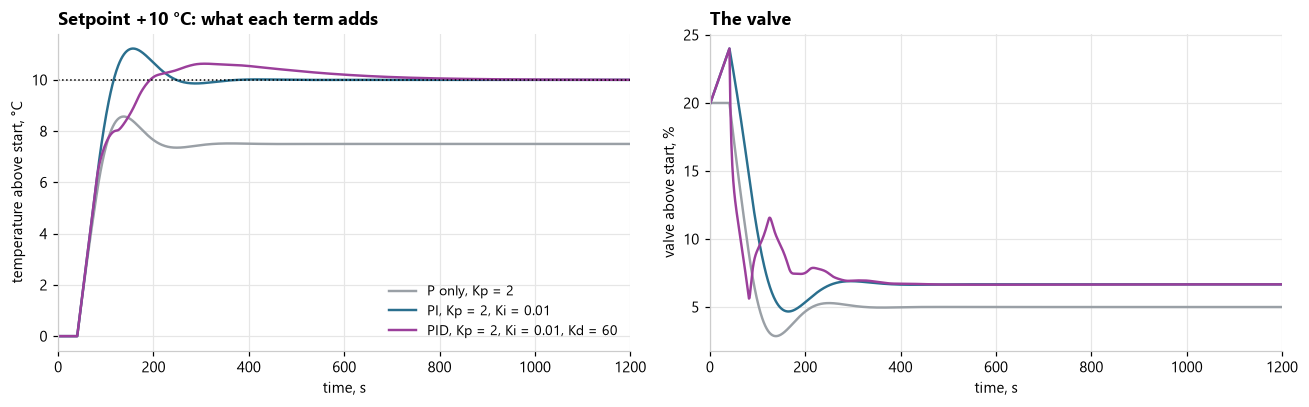

P only settles at 7.50 °C instead of 10


In [2]:
K_F, T_F, L_F = 1.5, 200.0, 40.0          # furnace: °C per %, s, s
R_STEP = 10.0                             # setpoint step, °C
U_LO, U_HI = -30.0, 70.0                  # valve travel around the operating point, %


def simulate(Kp, Ki, Kd, K=K_F, T=T_F, L=L_F, t_end=1500.0, dt=1.0, r=R_STEP,
             u_lo=U_LO, u_hi=U_HI, noise=0.0, seed=0):
    # Closed loop of a PID and a FOPDT plant. Gains may be arrays: one loop per element.
    # Returns t (steps,) and Y, U (steps, loops): temperature and valve above the start.
    gains = [np.atleast_1d(np.asarray(g, float)) for g in (Kp, Ki, Kd)]
    Kp, Ki, Kd = np.broadcast_arrays(*gains)
    n = Kp.size
    steps = int(t_end / dt)
    d = int(round(L / dt))                                   # dead time in steps
    a = np.exp(-dt / T)
    Tf = Kd / np.maximum(Kp, 1e-9) / 10           # derivative filter time constant, s

    y, integral, deriv, y_prev = (np.zeros(n) for _ in range(4))
    valve_queue = np.zeros((d + 1, n))            # commands on their way to the burner
    rng = np.random.default_rng(seed)
    Y, U = np.zeros((steps, n)), np.zeros((steps, n))
    for k in range(steps):
        y_meas = y
        if noise:
            y_meas = y + rng.normal(0, noise, n)
        e = r - y_meas

        # filtered derivative of the measurement, then the command within the valve limits
        if k:
            deriv = (Tf * deriv - Kd * (y_meas - y_prev)) / (Tf + dt)
        y_prev = y_meas
        u_raw = Kp * e + integral + deriv
        u = np.clip(u_raw, u_lo, u_hi)

        # anti-windup: no integration towards a limit the valve already sits at
        winding = (u != u_raw) & (np.sign(e) == np.sign(u_raw))
        integral = integral + np.where(winding, 0.0, Ki * e * dt)

        # the furnace sees the command sent d steps ago
        valve_queue = np.roll(valve_queue, -1, axis=0)
        valve_queue[-1] = u
        y = a * y + (1 - a) * K * valve_queue[0]
        Y[k], U[k] = y, u
    return np.arange(1, steps + 1) * dt, Y, U


hand = {"P only, Kp = 2": (2, 0, 0),
        "PI, Kp = 2, Ki = 0.01": (2, 0.01, 0),
        "PID, Kp = 2, Ki = 0.01, Kd = 60": (2, 0.01, 60)}
hand_gains = np.array(list(hand.values())).T     # rows Kp, Ki, Kd; columns: controllers
t, Y, U = simulate(*hand_gains)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for j, (name, c) in enumerate(zip(hand, [GREY, BLUE, PURPLE])):
    axes[0].plot(t, Y[:, j], color=c, label=name)
    axes[1].plot(t, U[:, j], color=c)
axes[0].axhline(R_STEP, color="black", ls=":", lw=1)
axes[0].set(xlabel="time, s", ylabel="temperature above start, °C", xlim=(0, 1200),
            title="Setpoint +10 °C: what each term adds")
axes[1].set(xlabel="time, s", ylabel="valve above start, %", xlim=(0, 1200),
            title="The valve")
axes[0].legend(fontsize=9)
fig.tight_layout()
plt.show()
print(f"P only settles at {Y[-1, 0]:.2f} °C instead of {R_STEP:.0f}")

- P only leaves a permanent error. To hold the furnace 10 °C hotter the valve must stay open by
  $10 / 1.5 = 6.7$ %, and a P controller opens the valve only while there is an error. At steady
  state $y = K K_p e$ and $e = r - y$, so $e = r / (1 + K K_p) = 10 / 4 = 2.5$ °C, and the furnace
  settles at 7.5 °C.
- The integral keeps adding the error up, so the valve keeps moving until the error is zero.
- The derivative reacts to how fast the temperature rises and closes the valve early, before the
  overshoot. Here it halves the overshoot, but with $K_d = 60$ it brakes too hard, and the
  temperature then crawls up to the setpoint.

Three numbers picked by hand already give a working loop, and it is hard to say by eye which of
the last two is better. The rest of the notebook is about choosing the three numbers on purpose.

---

# Part 2. Scoring a step response

Four numbers describe a step response:

| measure | definition | why the plant cares |
|---|---|---|
| overshoot | $(\max y - r) / r$, % | a furnace above the setpoint can spoil the parts |
| settling time | the last moment $\lvert e\rvert > 2\,\%$ of the step | when production can resume |
| IAE | $\int \lvert e\rvert\,dt$ | total error |
| **ITAE** | $\int t\,\lvert e\rvert\,dt$ | total error, with late errors weighted more |

ITAE is the usual cost for automatic tuning. The weight $t$ forgives the error right after the
step, which no controller can avoid (here 40 s pass before anything happens), and it punishes
slow settling and long oscillation. An error of 1 °C at minute 10 costs ten times as much as the
same error at minute 1. An optimiser needs a single number, and ITAE gives one that grows with
every kind of badness.

In [3]:
def step_metrics(t, Y, r=R_STEP):
    # Overshoot (%), 2 % settling time (s; inf if it never settles), IAE and ITAE
    # for every column of Y.
    e = r - Y
    dt = t[1] - t[0]
    overshoot = np.maximum(0, Y.max(axis=0) - r) / r * 100

    # settling time: the last moment outside the 2 % band; inf if the run ends outside it
    outside = np.abs(e) > 0.02 * r
    last_outside = np.zeros(Y.shape[1])
    for j, col in enumerate(outside.T):
        if col.any():
            last_outside[j] = t[np.flatnonzero(col)[-1]]
    settling = np.where(outside[-1], np.inf, last_outside)

    iae = np.abs(e).sum(axis=0) * dt
    itae = (t[:, None] * np.abs(e)).sum(axis=0) * dt
    return pd.DataFrame({"overshoot, %": overshoot, "settling, s": settling,
                         "IAE": iae, "ITAE": itae})


m = step_metrics(t, Y)
m.index = list(hand)
m.round(1)

,"overshoot, %","settling, s",IAE,ITAE
"P only, Kp = 2",0.000,inf,"4,193.400","2,824,536.700"
"PI, Kp = 2, Ki = 0.01",12.200,228.000,842.900,"49,211.700"
"PID, Kp = 2, Ki = 0.01, Kd = 60",6.300,602.000,"1,061.800","134,401.800"


The P controller never settles (its error stays at 2.5 °C), so its settling time is infinite and
its ITAE grows with the length of the run. Between the PI and the hand-picked PID the measures
disagree. The PID overshoots half as much (6.3 against 12.2 %), but it takes 602 s instead of
228 s to enter the 2 % band, and its ITAE is almost three times larger. The weight $t$ in ITAE is
what punishes that slow crawl.

---

# Part 3. Two classical baselines

## 3.1 Ziegler–Nichols, the closed-loop method (1942)

Switch off the integral and the derivative, and raise $K_p$ until the loop oscillates with a
constant amplitude. That gain is the **ultimate gain** $K_u$, and the period of the oscillation is
$P_u$. Then

$$K_p = 0.6\,K_u, \qquad T_i = P_u / 2, \qquad T_d = P_u / 8, \qquad K_i = K_p / T_i, \qquad K_d = K_p\,T_d.$$

$K_u$ and $P_u$ describe the loop at the edge of instability: the gain and the frequency at which
the dead time and the lag together turn the feedback around by half a cycle. The rule backs off
from that edge by a fixed factor. On a real furnace the experiment drives the plant to the edge,
which is why operators dislike it. On a model it is a bisection: a gain too low gives a decaying
oscillation, a gain too high a growing one.

## 3.2 SIMC (Skogestad, 2003)

A modern rule written for FOPDT models. It has one tuning knob, $\tau_c$, the desired closed-loop
time constant, usually set equal to $L$:

$$K_p = \frac{T}{K(\tau_c + L)}, \qquad T_i = \min\bigl(T,\ 4(\tau_c + L)\bigr), \qquad K_d = 0.$$

It gives a PI controller. The idea: ask the closed loop to respond like a first-order lag of
$\tau_c$ after the unavoidable dead time, and do not ask for anything faster than the dead time
allows. SIMC was designed to be robust; Part 9 tests that.

In [4]:
def grows(Kp):
    # Does a P-only loop with this gain oscillate with a growing amplitude? (no limits)
    t, Y, _ = simulate(Kp, 0, 0, t_end=2000, u_lo=-1e9, u_hi=1e9)
    y = Y[:, 0]
    swing_late = np.ptp(y[1500:])
    swing_early = np.ptp(y[1000:1500])
    return not swing_late <= swing_early      # an overflow to nan also counts as growing


# bisection on Kp: the edge between a decaying and a growing oscillation
lo, hi = 0.1, 20.0
for _ in range(40):
    mid = (lo + hi) / 2
    if grows(mid):
        hi = mid
    else:
        lo = mid
Ku = (lo + hi) / 2

# the period at the edge: mean distance between the peaks
t, Y, _ = simulate(Ku, 0, 0, t_end=2000, u_lo=-1e9, u_hi=1e9)
y = Y[:, 0]
peaks = [i for i in range(1001, 1999) if y[i] > y[i - 1] and y[i] >= y[i + 1]]
Pu = float(np.mean(np.diff(peaks)))
print(f"ultimate gain Ku = {Ku:.3f} %/°C, period Pu = {Pu:.1f} s")

Kp_zn = 0.6 * Ku
ZN = (Kp_zn, Kp_zn / (Pu / 2), Kp_zn * Pu / 8)

tau_c = L_F
Kp_simc = T_F / (K_F * (tau_c + L_F))
Ti_simc = min(T_F, 4 * (tau_c + L_F))
SIMC = (Kp_simc, Kp_simc / Ti_simc, 0.0)

baselines = {"Ziegler-Nichols": ZN, "SIMC": SIMC}
baseline_gains = pd.DataFrame(baselines, index=["Kp", "Ki", "Kd"]).T
print(baseline_gains.round(4).to_string())

t, Y, U = simulate(*baseline_gains.to_numpy().T)
m = step_metrics(t, Y)
m.index = list(baselines)
print()
print(m.round(1).to_string())

ultimate gain Ku = 5.603 %/°C, period Pu = 150.5 s
                   Kp    Ki     Kd
Ziegler-Nichols 3.362 0.045 63.247
SIMC            1.667 0.008  0.000

                 overshoot, %  settling, s       IAE        ITAE
Ziegler-Nichols        56.200      388.000 1,104.400 101,671.100
SIMC                    4.400      246.000   866.000  46,908.300


Ziegler–Nichols aims at a quarter decay ratio: every peak a quarter of the one before. For a
response that looks like a damped second-order system the decay ratio is the square of the first
overshoot, so a quarter decay means an overshoot of about half the step. The furnace shows 56 %.
SIMC, a PI without derivative, overshoots by a few percent and settles sooner, and by ITAE it wins
by a factor of two. Ziegler–Nichols was designed for load disturbances, and for a setpoint step it
is known to be aggressive. It is a weak baseline, so a fair comparison needs SIMC as well.

---

# Part 4. The cost landscape

Before running an optimiser, look at what it will search. Below is the ITAE of a PI controller
($K_d = 0$) over a grid of $K_p$ and $K_i$, 60 × 60 loops. Both axes are logarithmic. The white area
never enters the 2 % band within the 25-minute run: at the top right because the loop is unstable,
at the left and at the bottom because it is too sluggish.

best PI on the grid: Kp = 1.78, Ki = 0.0089, ITAE 46,510


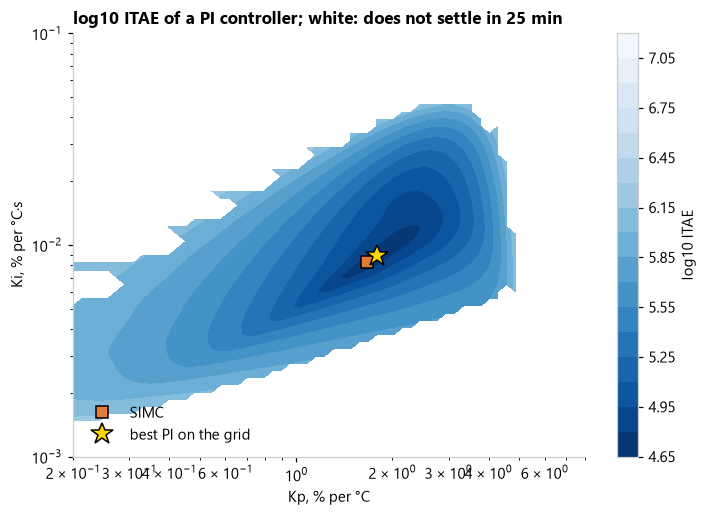

In [5]:
kp_axis = np.geomspace(0.2, 8, 60)
ki_axis = np.geomspace(1e-3, 0.1, 60)
KPg, KIg = np.meshgrid(kp_axis, ki_axis)
t, Y, _ = simulate(KPg.ravel(), KIg.ravel(), 0.0)
land = step_metrics(t, Y)
itae_map = land["ITAE"].to_numpy().reshape(KPg.shape).copy()
settles = np.isfinite(land["settling, s"].to_numpy().reshape(KPg.shape))
itae_map[~settles] = np.nan          # white on the map: never enters the 2 % band

k = np.nanargmin(itae_map)
PI_GRID = (KPg.flat[k], KIg.flat[k], 0.0)
print(f"best PI on the grid: Kp = {PI_GRID[0]:.2f}, Ki = {PI_GRID[1]:.4f}, "
      f"ITAE {itae_map.flat[k]:,.0f}")


def draw_landscape(ax, title=""):
    cs = ax.contourf(KPg, KIg, np.log10(itae_map), levels=20, cmap="Blues_r")
    ax.set(xscale="log", yscale="log", xlabel="Kp, % per °C", ylabel="Ki, % per °C·s")
    ax.plot(SIMC[0], SIMC[1], "s", color=ORANGE, mec="black", ms=8, label="SIMC")
    ax.plot(*PI_GRID[:2], "*", color="gold", mec="black", ms=15,
            label="best PI on the grid")
    ax.grid(False)
    if title:
        ax.set_title(title, fontsize=11)
    return cs


fig, ax = plt.subplots(figsize=(7.5, 5))
cs = draw_landscape(ax, "log10 ITAE of a PI controller; white: does not settle in 25 min")
fig.colorbar(cs, ax=ax, label="log10 ITAE")
ax.legend(loc="lower left")
plt.show()

The landscape is one long valley. It rises steeply towards the unstable corner at the top right
and gently towards the sluggish side. Note where SIMC sits: almost on top of the best PI. A
one-line rule written for FOPDT models finds the PI optimum that the grid needed 3600 loops for,
so whatever an optimiser adds on this furnace has to come from the derivative.

The grid of 3600 loops took a few seconds here. With the derivative added it would be 216 000
loops, and on a real plant each loop is a test run. Hence the optimisers.

---

# Part 5. A genetic algorithm

A genetic algorithm (GA) breeds a population of candidate tunings. Each **individual** is a vector
of gains $\mathbf{x} = (K_p, K_i, K_d)$, and its **fitness** is its ITAE (lower is better). One
**generation**:

1. selection by tournament: pick two individuals at random, and the better one becomes a parent.
   Good tunings breed more often, but a weak one still gets a chance;
2. crossover: a child $\mathbf{c} = \mathbf{a} + \mathbf{w} \odot (\mathbf{b} - \mathbf{a})$ is drawn
   on the line through its parents $\mathbf{a}$ and $\mathbf{b}$, every component of $\mathbf{w}$
   uniform in $[-0.25, 1.25]$, so a little beyond the parents on either side (blend crossover,
   BLX-$\alpha$ with $\alpha = 0.25$);
3. mutation: with probability 0.2 each gene is shifted by a normal random amount with a standard
   deviation of 10 % of its range;
4. elitism: the two best individuals pass to the next generation unchanged, so the best tuning
   found is never lost.

Crossover only explores the space between the tunings the population already has, and as the
population gathers in the valley it explores less and less. Mutation keeps throwing in genes from
outside that range, and the overshoot of $\alpha > 0$ lets the population drift beyond its own
edge.

Differential evolution from Week 9 is a close relative: it also mutates and crosses, but builds its
steps from the differences between members.

First on the two-gain PI problem, so that the population can be drawn on the landscape.

GA on PI: Kp = 1.795, Ki = 0.0090, ITAE 46,559 after 1500 loops


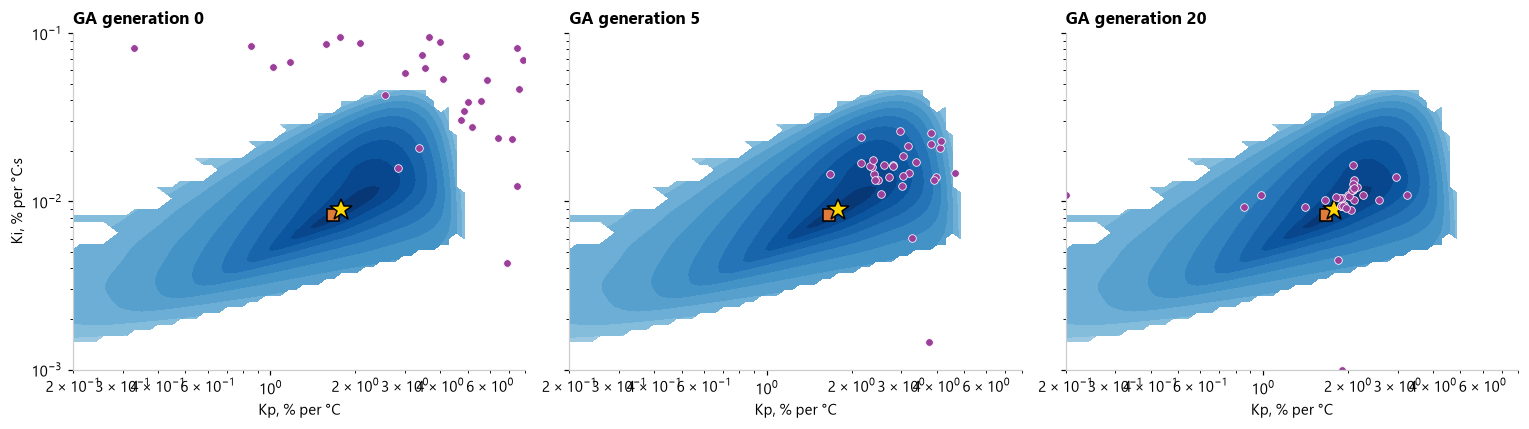

In [6]:
def itae_cost(P, **kw):
    # ITAE of every row of P = [Kp, Ki, Kd], shape (k, 3) -> (k,); unstable or
    # never-settling loops get their (huge) ITAE too. kw goes to simulate, e.g. L=...
    t, Y, _ = simulate(P[:, 0], P[:, 1], P[:, 2], **kw)
    return step_metrics(t, Y)["ITAE"].to_numpy()


def genetic_algorithm(cost, lo, hi, pop=30, generations=50, alpha=0.25, p_mut=0.2,
                      elite=2, seed=0, keep=()):
    # Costs pop * generations evaluations. Returns the best tuning, its cost, the best
    # cost after each generation, and snapshots of the population at the generations
    # in keep.
    rng = np.random.default_rng(seed)
    lo, hi = np.asarray(lo, float), np.asarray(hi, float)
    n_genes = len(lo)
    P = lo + (hi - lo) * rng.random((pop, n_genes))
    f = cost(P)
    best = [f.min()]
    snaps = {0: P.copy()}

    def parent():
        # tournament of two: the better of two random individuals
        i, j = rng.integers(0, pop, 2)
        return P[i] if f[i] < f[j] else P[j]

    for g in range(1, generations):
        children = [P[i] for i in np.argsort(f)[:elite]]          # elitism
        while len(children) < pop:
            a, b = parent(), parent()
            w = rng.uniform(-alpha, 1 + alpha, n_genes)
            child = a + w * (b - a)                                  # blend crossover
            mutate = rng.random(n_genes) < p_mut
            shift = rng.normal(0, 0.1, n_genes) * (hi - lo)
            child = child + mutate * shift
            children.append(np.clip(child, lo, hi))
        P = np.array(children)
        f = cost(P)
        best.append(min(best[-1], f.min()))
        if g in keep:
            snaps[g] = P.copy()
    return P[np.argmin(f)], f.min(), np.array(best), snaps


PI_LO, PI_HI = [0.2, 1e-3, 0.0], [8.0, 0.1, 0.0]
x, fx, hist, snaps = genetic_algorithm(itae_cost, PI_LO, PI_HI, keep=(5, 20))
print(f"GA on PI: Kp = {x[0]:.3f}, Ki = {x[1]:.4f}, ITAE {fx:,.0f} after {30 * 50} loops")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, g in zip(axes, [0, 5, 20]):
    draw_landscape(ax, f"GA generation {g}")
    ax.plot(snaps[g][:, 0], snaps[g][:, 1], "o", color=PURPLE, ms=5, mec="white", mew=0.5)
    if g:
        ax.set_ylabel("")
fig.tight_layout()
plt.show()

Generation 0 is scattered over the box. The box is linear and the plot logarithmic, so most points
sit at large $K_i$, at the top of the plot. In five generations the population has left the white
area, and by generation 20 it sits in the valley around the grid's best point. The GA reaches the
grid's answer with 1500 loops instead of 3600, on two gains. On three gains the grid would need
hundreds of thousands.

Now the full PID. The box: $K_p$ 0.1–10, $K_i$ 0–0.1, $K_d$ 0–300.

In [7]:
PID_LO, PID_HI = [0.1, 0.0, 0.0], [10.0, 0.1, 300.0]
GA, f_ga, hist_ga, _ = genetic_algorithm(itae_cost, PID_LO, PID_HI, seed=0)
print(f"GA on PID: Kp = {GA[0]:.3f}, Ki = {GA[1]:.4f}, Kd = {GA[2]:.1f}, "
      f"ITAE {f_ga:,.0f}")

GA on PID: Kp = 2.844, Ki = 0.0105, Kd = 40.4, ITAE 28,095


---

# Part 6. Particle swarm optimisation

A particle swarm (PSO) is a flock of points that fly through the box. Each particle $i$ has a
position $\mathbf{x}_i$ (a tuning) and a velocity $\mathbf{v}_i$, remembers its own best position
$\mathbf{p}_i$, and knows the best position of the whole swarm $\mathbf{g}$. Each step:

$$\mathbf{v}_i \leftarrow w\,\mathbf{v}_i + c_1 \mathbf{r}_1 \odot (\mathbf{p}_i - \mathbf{x}_i) + c_2 \mathbf{r}_2 \odot (\mathbf{g} - \mathbf{x}_i), \qquad \mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i,$$

with the components of $\mathbf{r}_1, \mathbf{r}_2$ uniform in $[0, 1]$, drawn anew for every
coordinate. Three pulls act on a particle. Inertia $w = 0.7$ keeps it going, the cognitive term
$c_1 = 1.5$ pulls it back to its own best, the social term $c_2 = 1.5$ to the swarm's best.
Positions are clipped to the box.

Think of a particle on a spring tied to two anchors, $\mathbf{p}_i$ and $\mathbf{g}$, with
friction. With $w < 1$ the motion is damped, so the particle oscillates around a point between the
two anchors and settles; the random factors make it overshoot by a different amount each time, and
on the way it samples the region around the anchors. When it finds a better point, the anchor
moves.

PSO has no selection and no offspring: every particle survives and keeps learning from the others.
It usually converges faster than a GA, and it is more likely to collapse early onto one point.

PSO on PI: Kp = 1.742, Ki = 0.0087, ITAE 46,406


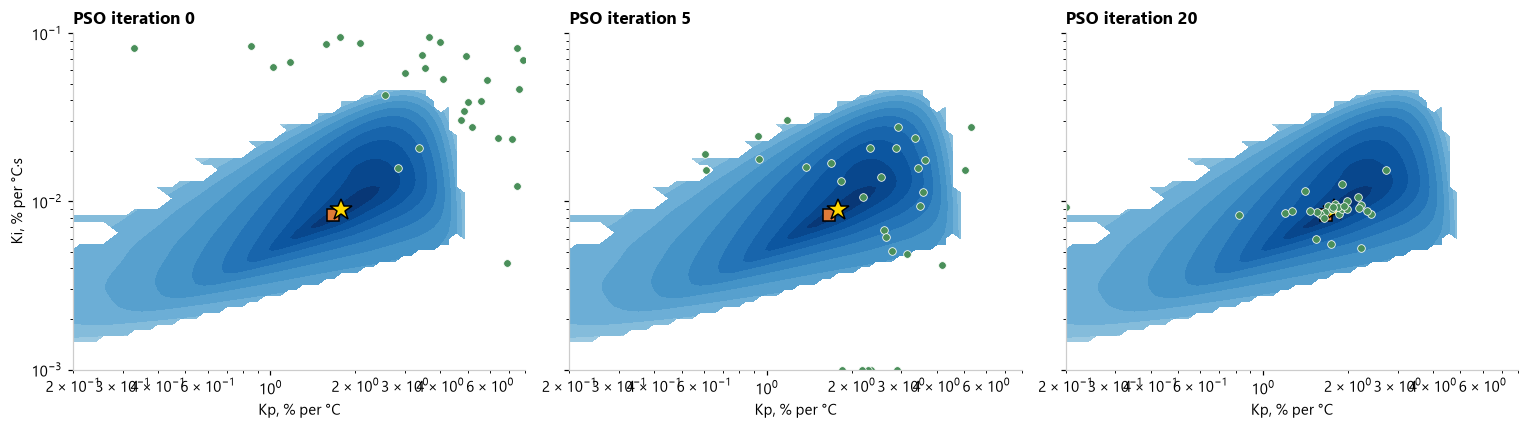

PSO on PID: Kp = 2.753, Ki = 0.0101, Kd = 40.7, ITAE 26,787


In [8]:
def particle_swarm(cost, lo, hi, particles=30, iterations=50, w=0.7, c1=1.5, c2=1.5,
                   seed=0, keep=()):
    # Costs particles * iterations evaluations. Returns the swarm's best tuning, its cost,
    # the best cost after each iteration, and snapshots of the positions at the iterations
    # in keep.
    rng = np.random.default_rng(seed)
    lo, hi = np.asarray(lo, float), np.asarray(hi, float)
    X = lo + (hi - lo) * rng.random((particles, len(lo)))
    V = np.zeros_like(X)
    f = cost(X)
    P, fP = X.copy(), f.copy()                 # every particle's own best and its cost
    g = P[np.argmin(fP)].copy()                # the swarm's best
    best = [fP.min()]
    snaps = {0: X.copy()}

    for it in range(1, iterations):
        r1, r2 = rng.random(X.shape), rng.random(X.shape)
        V = w * V + c1 * r1 * (P - X) + c2 * r2 * (g - X)
        X = np.clip(X + V, lo, hi)
        f = cost(X)

        # update the memories
        better = f < fP
        P[better], fP[better] = X[better], f[better]
        g = P[np.argmin(fP)].copy()
        best.append(fP.min())
        if it in keep:
            snaps[it] = X.copy()
    return g, fP.min(), np.array(best), snaps


x, fx, _, snaps = particle_swarm(itae_cost, PI_LO, PI_HI, keep=(5, 20))
print(f"PSO on PI: Kp = {x[0]:.3f}, Ki = {x[1]:.4f}, ITAE {fx:,.0f}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, g in zip(axes, [0, 5, 20]):
    draw_landscape(ax, f"PSO iteration {g}")
    ax.plot(snaps[g][:, 0], snaps[g][:, 1], "o", color=GREEN, ms=5, mec="white", mew=0.5)
    if g:
        ax.set_ylabel("")
fig.tight_layout()
plt.show()

PSO, f_pso, hist_pso, _ = particle_swarm(itae_cost, PID_LO, PID_HI, seed=0)
print(f"PSO on PID: Kp = {PSO[0]:.3f}, Ki = {PSO[1]:.4f}, Kd = {PSO[2]:.1f}, "
      f"ITAE {f_pso:,.0f}")

At iteration 5 the swarm is still spread wider than the GA population, and a few particles sit on
the lower bound of $K_i$: particles carry momentum and fly past the valley before they turn. By
iteration 20 most of the swarm is in the valley near the star, about as close together as the GA
population. On the PID both methods land on similar gains.

---

# Part 7. An equal budget

Each method gets 1500 loop simulations, the same as above, and runs with ten seeds:

- GA and PSO as written, 30 × 50;
- differential evolution from `scipy` with a population of 10 per gain (30 loops per generation),
  50 generations, no polishing;
- random search: 1500 random tunings in the box, in 50 batches of 30.

`LoopCounter` wraps the cost: it counts the loops each run really simulated and records the best
ITAE after every call. The cell checks that every run used exactly 1500.

final ITAE after 1500 loops, 10 seeds
             best     median      worst
GA     26,938.000 27,997.000 33,824.000
PSO    26,562.000 26,702.000 27,192.000
DE     26,494.000 26,496.000 26,500.000
random 35,774.000 52,075.000 72,605.000


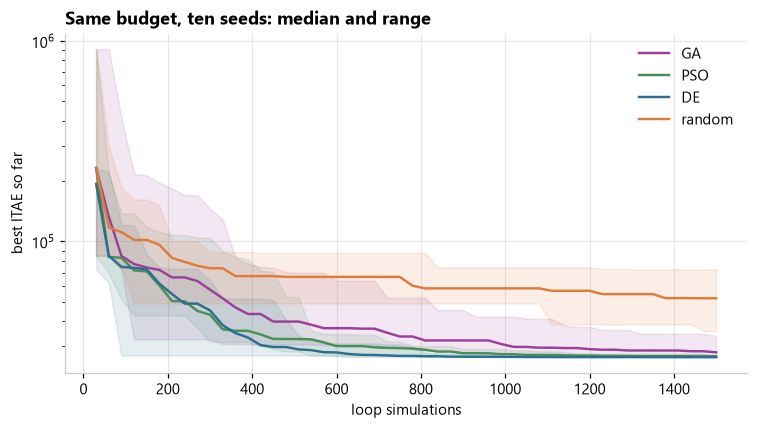

In [9]:
from scipy.optimize import differential_evolution

BUDGET = 1500


class LoopCounter:
    # Wraps a cost of many tunings at once, (k, 3) -> (k,). Counts the loops simulated
    # and keeps the best cost seen after each call.
    def __init__(self, cost):
        self.cost, self.loops, self.best = cost, 0, []

    def __call__(self, P):
        f = self.cost(P)
        self.loops += len(P)
        self.best.append(min(self.best[-1] if self.best else np.inf, f.min()))
        return f


lo3, hi3 = np.array(PID_LO), np.array(PID_HI)
runs = {"GA": [], "PSO": [], "DE": [], "random": []}     # a LoopCounter per seed
for seed in range(10):
    c = LoopCounter(itae_cost)
    genetic_algorithm(c, PID_LO, PID_HI, seed=seed)
    runs["GA"].append(c)

    c = LoopCounter(itae_cost)
    particle_swarm(c, PID_LO, PID_HI, seed=seed)
    runs["PSO"].append(c)

    c = LoopCounter(itae_cost)                            # DE hands over shape (3, k)
    bounds = list(zip(PID_LO, PID_HI))
    differential_evolution(lambda Xt: c(Xt.T), bounds, popsize=10, maxiter=49, tol=0,
                           polish=False, seed=seed, vectorized=True, updating="deferred")
    runs["DE"].append(c)

    c = LoopCounter(itae_cost)
    draws = np.random.default_rng(seed).random((BUDGET, 3))
    random_tunings = lo3 + (hi3 - lo3) * draws
    for batch in np.split(random_tunings, 50):
        c(batch)
    runs["random"].append(c)

loops_used = [c.loops for cs in runs.values() for c in cs]
assert all(n == BUDGET for n in loops_used), "a method got a different budget"

final_stats = {}
for name, cs in runs.items():
    final = [c.best[-1] for c in cs]
    final_stats[name] = {"best": np.min(final), "median": np.median(final),
                         "worst": np.max(final)}
summary = pd.DataFrame(final_stats).T
print(f"final ITAE after {BUDGET} loops, 10 seeds")
print(summary.round(0).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
for (name, cs), col in zip(runs.items(), [PURPLE, GREEN, BLUE, ORANGE]):
    H = np.array([c.best for c in cs])                    # seeds x calls
    x_calls = np.arange(1, H.shape[1] + 1) * BUDGET // H.shape[1]
    ax.plot(x_calls, np.median(H, axis=0), color=col, label=name)
    ax.fill_between(x_calls, H.min(0), H.max(0), color=col, alpha=0.12)
ax.set(yscale="log", xlabel="loop simulations", ylabel="best ITAE so far",
       title="Same budget, ten seeds: median and range")
ax.legend()
plt.show()

DE finds the same tuning on every seed. PSO is 0.8 % above it in the median and 2.6 % on its worst
seed. The GA is behind: 6 % above DE in the median, and one seed stopped 28 % above, because its
population lost its diversity early. Random search is far behind. The spread of DE and PSO over
seeds is narrow because this landscape has a single valley. This is the comparison the practice
asks for, and the honest result is usually like this one: the choice between GA, PSO and DE
matters much less than the choice of the cost function, as Part 9 shows.

---

# Part 8. Four tunings side by side

                   Kp    Ki     Kd  overshoot, %  settling, s       IAE        ITAE  max valve, %
Ziegler-Nichols 3.362 0.045 63.247        56.165      388.000 1,104.421 101,671.139        51.491
SIMC            1.667 0.008  0.000         4.445      246.000   865.958  46,908.276        20.000
GA              2.844 0.011 40.450         7.668      188.000   677.633  28,095.335        32.654
PSO             2.753 0.010 40.730         4.774      187.000   675.373  26,786.810        31.577


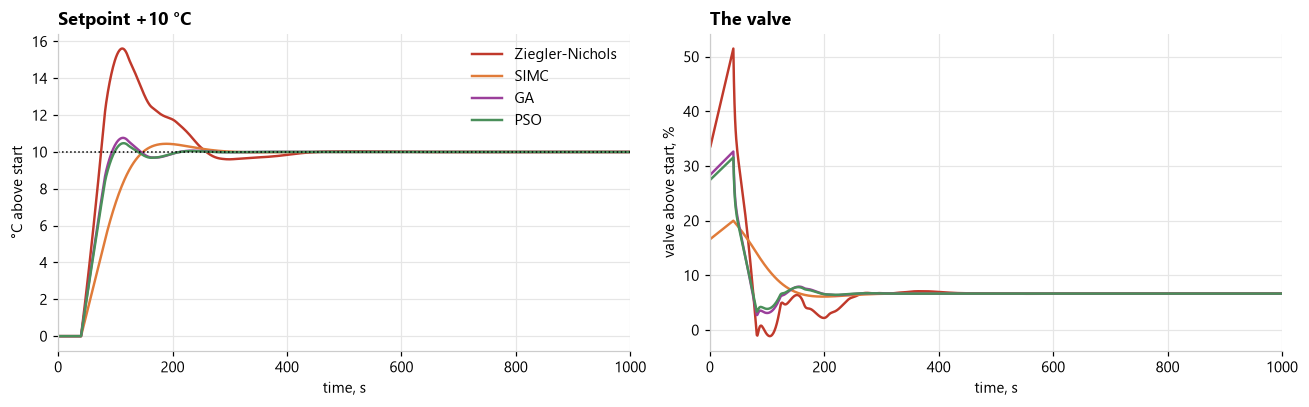

In [10]:
tunings = {"Ziegler-Nichols": ZN, "SIMC": SIMC, "GA": tuple(GA), "PSO": tuple(PSO)}
tuning_gains = np.array(list(tunings.values())).T     # rows Kp, Ki, Kd; columns: tunings
t, Y, U = simulate(*tuning_gains)

table = step_metrics(t, Y)
table.index = list(tunings)
table.insert(0, "Kd", tuning_gains[2])
table.insert(0, "Ki", tuning_gains[1])
table.insert(0, "Kp", tuning_gains[0])
table["max valve, %"] = U.max(axis=0)
print(table.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for j, (name, c) in enumerate(zip(tunings, [RED, ORANGE, PURPLE, GREEN])):
    axes[0].plot(t, Y[:, j], color=c, label=name)
    axes[1].plot(t, U[:, j], color=c)
axes[0].axhline(R_STEP, color="black", ls=":", lw=1)
axes[0].set(xlabel="time, s", ylabel="°C above start", xlim=(0, 1000),
            title="Setpoint +10 °C")
axes[1].set(xlabel="time, s", ylabel="valve above start, %", xlim=(0, 1000),
            title="The valve")
axes[0].legend()
fig.tight_layout()
plt.show()

GA and PSO cut the ITAE of Ziegler–Nichols by about four times and that of SIMC by almost half,
with a small overshoot and the shortest settling time. Look at the valve, though: the optimised
controllers open it by about 32 % at the start, SIMC by 20 %. ITAE says nothing about the valve, so
the optimiser uses as much of it as helps.

---

# Part 9. Robustness to the dead time

The model says $L$ = 40 s. In March, with a different gas pressure and a fouled burner, the real
dead time can be 50 or 60 s. A controller tuned on the model runs on the real furnace. Below, each
tuning is run with the dead time 1.25, 1.5 and 2 times longer than the one it was tuned for.

dead time           x1  x1.25    x1.5      x2
tuning                                       
GA               8.000 27.000  47.000  85.000
PSO              5.000 24.000  42.000  79.000
SIMC             4.000 14.000  26.000  51.000
Ziegler-Nichols 56.000 95.000 135.000 220.000

dead time            x1   x1.25      x1.5        x2
tuning                                             
GA              188.000 327.000   587.000       inf
PSO             187.000 318.000   569.000       inf
SIMC            246.000 279.000   443.000 1,039.000
Ziegler-Nichols 388.000 394.000 1,288.000       inf


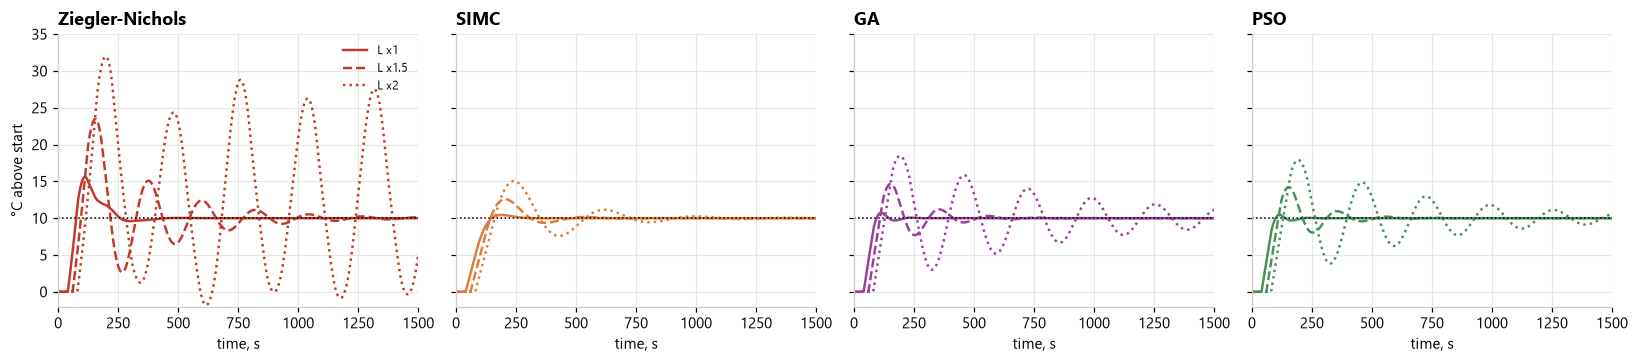

In [11]:
rows = []
for factor in [1.0, 1.25, 1.5, 2.0]:
    t, Y, _ = simulate(*tuning_gains, L=L_F * factor)
    m = step_metrics(t, Y)
    for name, (_, r) in zip(tunings, m.iterrows()):
        rows.append({"tuning": name, "dead time": f"x{factor:g}",
                     "overshoot, %": r["overshoot, %"], "settling, s": r["settling, s"],
                     "ITAE": r["ITAE"]})
robust = pd.DataFrame(rows).pivot(index="tuning", columns="dead time")
print(robust["overshoot, %"].round(0).to_string())
print()
print(robust["settling, s"].round(0).to_string())

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, (name, gains), c in zip(axes, tunings.items(), [RED, ORANGE, PURPLE, GREEN]):
    for factor, ls in zip([1.0, 1.5, 2.0], ["-", "--", ":"]):
        t, Y, _ = simulate(*gains, L=L_F * factor)
        ax.plot(t, Y[:, 0], color=c, ls=ls, label=f"L x{factor:g}")
    ax.set(title=name, xlabel="time, s", xlim=(0, 1500), ylim=(-2, 35))
    ax.axhline(R_STEP, color="black", ls=":", lw=1)
axes[0].set_ylabel("°C above start")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The ranking turns over. With the dead time doubled, Ziegler–Nichols and both optimised tunings
oscillate without settling; SIMC overshoots by half and still settles. The optimiser found the
tuning that is best *for the model*, and Part 4 showed where such tunings live: close to the edge
of stability.

Why the dead time decides it: a delay $L$ shifts a sine of frequency $\omega$ by the phase
$\omega L$ without changing its amplitude. A fast, aggressive loop works at a high frequency, so
the same extra delay costs it more phase, and it loses its stability margin first. SIMC asks for a
slower loop ($\tau_c = L$) and has margin to spare.

## 9.1 A robust cost

The fix is in the cost, not in the optimiser. Tune for the worst of three furnaces, the model and
two with longer dead times:

$$J(K_p, K_i, K_d) = \max_{L \in \{40,\ 60,\ 80\}} \text{ITAE}(K_p, K_i, K_d;\ L).$$

In [12]:
def robust_cost(P):
    return np.max([itae_cost(P, L=L_F * f) for f in (1.0, 1.5, 2.0)], axis=0)


ROB, f_rob, _, _ = particle_swarm(robust_cost, PID_LO, PID_HI, seed=0)
print(f"robust PSO: Kp = {ROB[0]:.3f}, Ki = {ROB[1]:.4f}, Kd = {ROB[2]:.1f}")

rows = []
for name, gains in {"PSO (nominal)": PSO, "PSO (robust)": ROB, "SIMC": SIMC}.items():
    for factor in [1.0, 1.5, 2.0]:
        t, Y, _ = simulate(*gains, L=L_F * factor)
        m = step_metrics(t, Y).iloc[0]
        rows.append({"tuning": name, "dead time": f"x{factor:g}", "ITAE": m["ITAE"],
                     "overshoot, %": m["overshoot, %"], "settling, s": m["settling, s"]})
robust_table = pd.DataFrame(rows).set_index(["tuning", "dead time"])
robust_table.round(1)

robust PSO: Kp = 1.515, Ki = 0.0056, Kd = 37.3


ITAE  overshoot, %  settling, s
tuning        dead time                                         
PSO (nominal) x1           26,786.800         4.800      187.000
              x1.5        161,810.100        42.300      569.000
              x2        1,613,063.900        79.100          inf
PSO (robust)  x1          113,507.700         0.000      378.000
              x1.5         89,922.700         0.000      301.000
              x2          112,557.700        10.400      369.000
SIMC          x1           46,908.300         4.400      246.000
              x1.5        145,375.200        25.800      443.000
              x2          544,627.200        50.500    1,039.000

The robust tuning pays on the nominal furnace: ITAE 114 thousand against 27 thousand for the
nominal PSO and 47 thousand for SIMC, no overshoot, but 378 s to settle. In exchange its response
hardly changes as the dead time grows. At twice the dead time it overshoots by 10 % and settles in
369 s, while the nominal tuning never settles and SIMC needs 1039 s. Every tuning trades
performance on the model against safety on the plant; the optimiser only makes the trade visible.
Practice 6 asks you to measure its price.

---

# Part 10. Noise and the derivative

The thermocouple is noisy: normal noise with a standard deviation of 0.2 °C. The derivative term
differentiates the measurement, noise included. Below are the same four controllers with that
noise. The valve travel is the total distance the valve moves in 25 minutes,
$\sum |u_{k+1} - u_k|$; valves wear out with travel.

                    Kd  valve travel, %        ITAE
Ziegler-Nichols 63.200       10,393.200 154,037.700
SIMC             0.000          560.700  66,018.300
GA              40.400        7,915.600  66,454.400
PSO             40.700        7,831.100  67,921.900


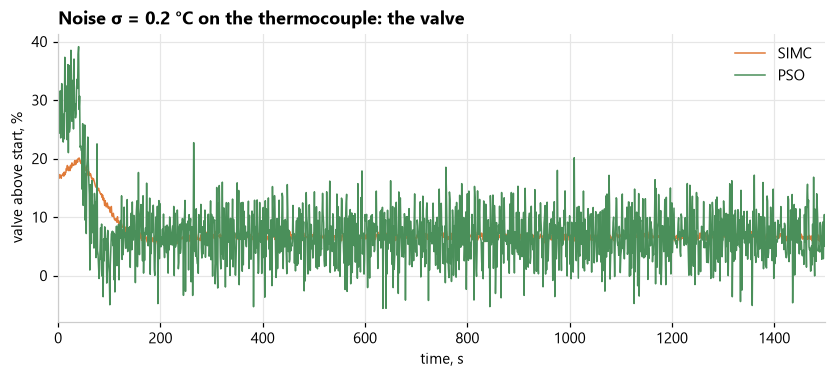

In [13]:
t, Y, U = simulate(*tuning_gains, noise=0.2)
travel = np.abs(np.diff(U, axis=0)).sum(axis=0)
itae_noisy = step_metrics(t, Y)["ITAE"].to_numpy()
noisy = pd.DataFrame({"Kd": tuning_gains[2], "valve travel, %": travel,
                      "ITAE": itae_noisy}, index=list(tunings))
print(noisy.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 3.4))
for j, (name, c) in enumerate(zip(tunings, [RED, ORANGE, PURPLE, GREEN])):
    if name in ("SIMC", "PSO"):
        ax.plot(t, U[:, j], color=c, lw=1, label=name)
ax.set(xlabel="time, s", ylabel="valve above start, %", xlim=(0, 1500),
       title="Noise σ = 0.2 °C on the thermocouple: the valve")
ax.legend()
plt.show()

The controllers with a derivative turn sensor noise into valve movement: the PSO tuning moves the
valve 14 times more than SIMC, which has no derivative. A derivative of white noise is large
because the noise changes sign every second; the filter cuts the fastest part, but
$K_d / T_f = 10 K_p$ still multiplies the rest. And the extra travel buys nothing: with the noise,
the ITAE of the PSO tuning (68 thousand) is no better than SIMC's (66 thousand), because the
jittering valve shakes the temperature too. The optimiser chose $K_d$ on a noise-free model and
could not see this. If the valve matters, its travel goes into the cost, for example
$J = \text{ITAE} + \mu \cdot \text{travel}$, and the noise goes into the model.

**Why does the derivative term amplify noise, and what does the filter change?**

<details><summary>Answer</summary>

Split the measurement into sinusoids. One of them, $a \sin \omega t$, has the derivative
$a\,\omega \cos \omega t$: differentiation multiplies its amplitude by $\omega$. The loop works
slowly, near $\omega_u = 2\pi / P_u$, while noise sampled every second has components up to
$\pi$ rad/s, much faster. A bare $K_d\,s$ would multiply those by $K_d\,\omega$, more the faster
they are. The filter turns the term into $K_d\,s / (T_f s + 1)$, whose gain

$$\frac{K_d\,\omega}{\sqrt{1 + (T_f\,\omega)^2}} \;\to\; \frac{K_d}{T_f} = 10\,K_p \quad (\omega \gg 1/T_f)$$

stops growing at ten times the proportional gain. The cell below prints this gain for the PSO
tuning.

</details>

In [14]:
# Gain of the PSO derivative: valve % per °C of a sinusoid at the frequency omega
Kp_pso, Kd_pso = PSO[0], PSO[2]
Tf_pso = Kd_pso / Kp_pso / 10
omega_u = 2 * np.pi / Pu                    # where the loop works
for omega in [omega_u, 0.3, 1.0, np.pi]:
    bare = Kd_pso * omega
    filtered = bare / np.sqrt(1 + (Tf_pso * omega) ** 2)
    print(f"omega = {omega:.3f} rad/s: bare Kd*omega = {bare:6.1f}, "
          f"filtered = {filtered:5.1f}")
print(f"ceiling Kd / Tf = 10 Kp = {10 * Kp_pso:.1f}, the P term alone {Kp_pso:.2f}")

omega = 0.042 rad/s: bare Kd*omega =    1.7, filtered =   1.7
omega = 0.300 rad/s: bare Kd*omega =   12.2, filtered =  11.2
omega = 1.000 rad/s: bare Kd*omega =   40.7, filtered =  22.8
omega = 3.142 rad/s: bare Kd*omega =  128.0, filtered =  26.9
ceiling Kd / Tf = 10 Kp = 27.5, the P term alone 2.75


---

## Where this goes next

Practice 6 does the same for a heat exchanger. You identify its FOPDT model from a step test, tune
it by Ziegler–Nichols, GA and PSO on the same budget, check the tunings on the real exchanger, and
measure what robustness to the dead time costs.

## Further reading

- Model predictive control (MPC) uses a model like the FOPDT here to predict the plant a few
  minutes ahead and chooses the next valve moves by solving a small optimisation, with the valve
  limits written in as constraints. Refineries and chemical plants run it on units where several
  valves and temperatures interact and one PID per loop is not enough. A standard text: Rawlings,
  Mayne and Diehl, *Model Predictive Control: Theory, Computation, and Design*, 2nd ed., 2017.